In [2]:
# pip install accelerate
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

import matplotlib.pyplot as plt

checkpoint = "HuggingFaceTB/SmolLM-135M"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint)

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

In [7]:
inputs = tokenizer.encode(f"What is the name of the newest pope:", return_tensors="pt")
inputs

tensor([[ 1780,   314,   260,  1462,   282,   260, 22947, 25679,    42]])

In [8]:
tokenizer.decode(model.generate(inputs, do_sample=False, max_new_tokens=5))

['What is the name of the newest pope:\nThe current pope is']

In [25]:
ids = inputs

top5_ids = []
top5_logits = []
for _ in range(10):
    with torch.no_grad():
        logits = model(ids).logits
        
    next_top5 = logits[0, -1].argsort()[-5:]
    
    top5_ids.append(next_top5)
    top5_logits.append(logits[0, -1, next_top5].float())
    
    
    next_id = next_top5[-1].view(1,1)
    ids = torch.cat([ids, next_id], dim=1)
    
print(tokenizer.decode(ids[0]))

What is the name of the newest pope:
The current pope is the current pope is the


In [26]:
index_lists = lambda i: (top5_ids[i], top5_logits[i]) 

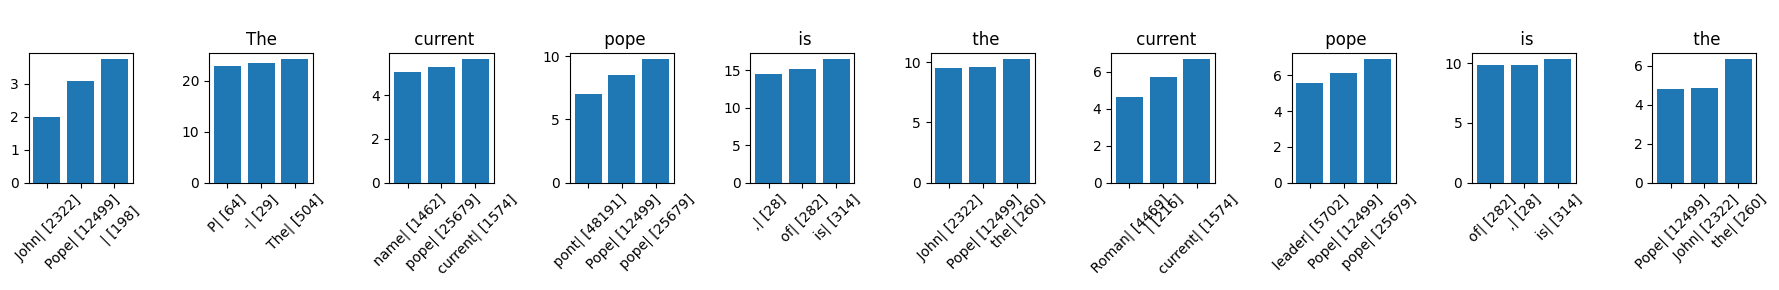

In [32]:
values = list(range(9, ids.shape[-1]))
plt.figure(figsize=(18,3), )
for i,j in enumerate(values):
    _ids, logits = index_lists(i)
    plt.subplot(1,len(values), 1+i)
    plt.bar([1,2,3], logits[-3:])
    plt.xticks([1,2,3], [f"{tokenizer.decode(x)}| [{x}]" for x in _ids[-3:]], rotation=45)
    plt.title(tokenizer.decode(_ids[-1]))

plt.tight_layout()
plt.show()
    